# 04 — FEATURE COLOR MOMENTS | KNN (CS231)


In [2]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from itertools import product
import sys

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
from IPython.display import display

PROJECT_ROOT = Path(r"C:\CS231")
DATA_ROOT = PROJECT_ROOT / "DATA"

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.evaluation.value_metrics import evaluate_classification

## 1. Đọc dữ liệu

In [3]:
def load_images_from_folder(folder):
    images = []
    labels = []
    folder = Path(folder)


    class_names = sorted(
        [d.name for d in folder.iterdir() if d.is_dir() and d.name.isdigit()],
        key=int
    )

    for class_name in class_names:
        class_folder = folder / class_name
        for img_path in sorted(class_folder.glob("*.png")):
            img = cv2.imread(str(img_path))
            if img is None:
                continue
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            images.append(img)
            labels.append(int(class_name))

    return images, labels, class_names

In [4]:
train_folder = DATA_ROOT / "train"
dev_folder = DATA_ROOT / "dev"

train_images, train_labels, train_class_names = load_images_from_folder(train_folder)
dev_images, dev_labels, dev_class_names = load_images_from_folder(dev_folder)

y_train = np.asarray(train_labels, dtype=np.int64)
y_dev = np.asarray(dev_labels, dtype=np.int64)

print(f"Số ảnh train: {len(train_images)} | Nhãn: {len(y_train)}")
print(f"Số ảnh dev:   {len(dev_images)} | Nhãn: {len(y_dev)}")
print("Các mệnh giá (VND):", train_class_names)
print("Shape ảnh train đầu tiên:", train_images[0].shape)

Số ảnh train: 12494 | Nhãn: 12494
Số ảnh dev:   1564 | Nhãn: 1564
Các mệnh giá (VND): ['10000', '20000', '50000', '100000', '200000', '500000']
Shape ảnh train đầu tiên: (640, 640, 3)


## 2. Trích xuất Color Moments đúng theo lab

Hàm `compute_moment_feature()` của lab dùng ba thống kê cho từng kênh RGB:

- **Mean (μ):** cường độ trung bình của kênh.
- **Standard Deviation (σ):** độ phân tán quanh trung bình.
- **Skewness:** mức bất đối xứng của phân bố cường độ, tính đúng theo công thức của lab: `mean(((image - mean) / (std + 1e-6)) ** 3)`.

Kết quả là **3 mean + 3 std + 3 skewness = 9 chiều**. Khác với Histogram RGB/HSV, ở đây **không có bước chuẩn hóa L2** trong hàm của lab.

In [5]:
FEATURE_NAMES = [
    "mean_R", "mean_G", "mean_B",
    "std_R", "std_G", "std_B",
    "skew_R", "skew_G", "skew_B",
]


def extract_color_moments(image):
    mean = np.mean(image, axis=(0, 1))
    std = np.std(image, axis=(0, 1))
    skewness = np.mean(((image - mean) / (std + 1e-6)) ** 3, axis=(0, 1))
    return np.concatenate([mean, std, skewness])

In [6]:
sample_rgb = train_images[0]
sample_moments = extract_color_moments(sample_rgb)

print("Ảnh RGB mẫu:", sample_rgb.shape)
print("Color Moments shape:", sample_moments.shape)
print("Dtype:", sample_moments.dtype)
print("Vector 9 chiều:", sample_moments)

display(pd.DataFrame({"feature": FEATURE_NAMES, "value": sample_moments}))

Ảnh RGB mẫu: (640, 640, 3)
Color Moments shape: (9,)
Dtype: float64
Vector 9 chiều: [ 1.00879207e+02  1.06374807e+02  1.07874370e+02  5.58173987e+01
  4.81670006e+01  4.87078396e+01 -1.20248620e-01 -7.67992136e-03
 -8.53893137e-03]


,feature,value
0,mean_R,100.879207
1,mean_G,106.374807
2,mean_B,107.874370
3,std_R,55.817399
4,std_G,48.167001
5,std_B,48.707840
6,skew_R,-0.120249
7,skew_G,-0.007680
8,skew_B,-0.008539


## 3. Trực quan hóa Color Moments của một ảnh


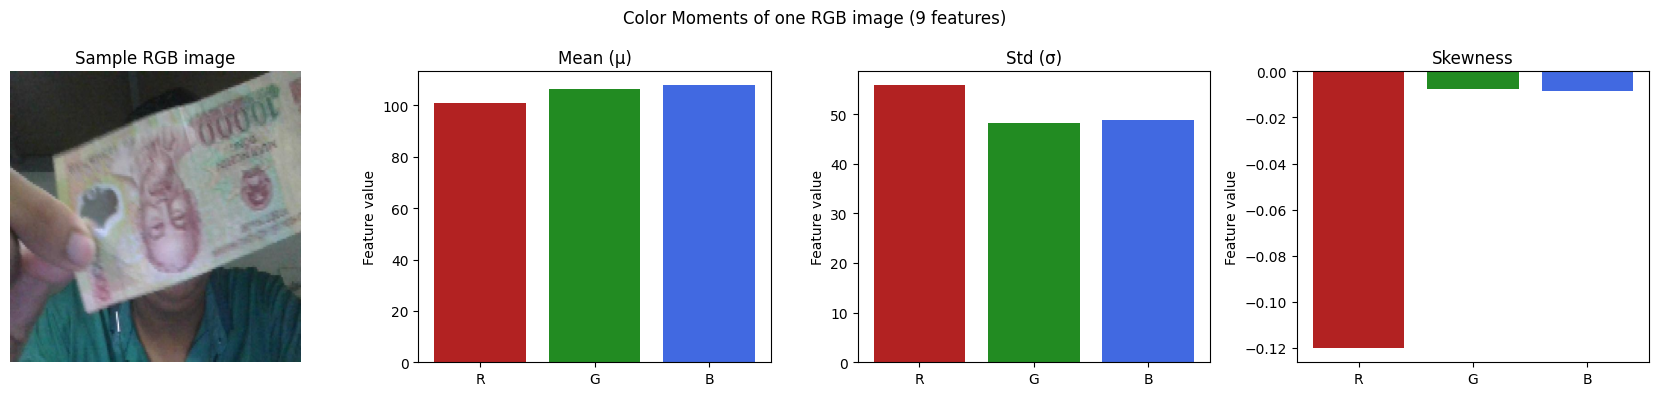

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
axes[0].imshow(sample_rgb)
axes[0].set_title("Sample RGB image")
axes[0].axis("off")

channel_names = ["R", "G", "B"]
channel_colors = ["firebrick", "forestgreen", "royalblue"]

for ax, values, title in zip(
    axes[1:],
    [sample_moments[:3], sample_moments[3:6], sample_moments[6:9]],
    ["Mean (μ)", "Std (σ)", "Skewness"],
):
    ax.bar(channel_names, values, color=channel_colors)
    ax.set_title(title)
    ax.set_ylabel("Feature value")
    ax.axhline(0, color="black", linewidth=0.7)

plt.suptitle("Color Moments of one RGB image (9 features)")
plt.tight_layout()
plt.show()

**Gợi ý nhận xét:** Trong ảnh mẫu, kênh nào có mean lớn nhất? Kênh nào có std cao nhất? Skewness âm/dương biểu thị điều gì về độ lệch của phân bố? Không suy ra mệnh giá từ một ảnh đơn lẻ; cần chạy và so sánh KNN trên dev.

## 4. Trích xuất ma trận feature train / dev

In [8]:
X_train_moments = np.asarray(
    [extract_color_moments(img) for img in train_images],
    dtype=np.float64
)
X_dev_moments = np.asarray(
    [extract_color_moments(img) for img in dev_images],
    dtype=np.float64
)

print("Train:", X_train_moments.shape, y_train.shape)
print("Dev:  ", X_dev_moments.shape, y_dev.shape)

Train: (12494, 9) (12494,)
Dev:   (1564, 9) (1564,)


In [9]:
feature_ranges = pd.DataFrame({
    "feature": FEATURE_NAMES,
    "min_train": X_train_moments.min(axis=0),
    "median_train": np.median(X_train_moments, axis=0),
    "max_train": X_train_moments.max(axis=0),
})
display(feature_ranges)

,feature,min_train,median_train,max_train
0,mean_R,16.317126,149.948921,248.346016
1,mean_G,18.928713,142.142424,250.949729
2,mean_B,14.675491,134.520728,250.593624
3,std_R,10.686837,49.353415,93.651948
4,std_G,13.741775,49.808283,89.901102
5,std_B,6.830908,53.148281,98.101044
6,skew_R,-5.996477,-0.419143,2.794721
7,skew_G,-6.068267,-0.292511,2.835611
8,skew_B,-8.103123,-0.189649,3.378263


## 5. Huấn luyện KNN — Grid Search độc lập cho Color Moments

In [10]:
n_neighbors_options = range(1, 11)
weight_options = ["uniform", "distance"]
metric_options = [
    "braycurtis",
    "canberra",
    "correlation",
    "cosine",
    "euclidean",
    "minkowski",
]

results_moments = []

for order, (k, weight, metric) in enumerate(
    product(n_neighbors_options, weight_options, metric_options)
):
    knn = KNeighborsClassifier(
        n_neighbors=k,
        weights=weight,
        metric=metric,
        algorithm="brute"
    )
    knn.fit(X_train_moments, y_train)
    y_pred = knn.predict(X_dev_moments)
    scores = evaluate_classification(y_dev, y_pred)

    results_moments.append({
        "k": k,
        "weights": weight,
        "metric": metric,
        "macro_f1": scores["macro_f1"],
        "mae_vnd": scores["mae_vnd"],
        "accuracy": scores["accuracy"],
        "_order": order,
    })

df_results_moments = (
    pd.DataFrame(results_moments)
    .sort_values(
        ["macro_f1", "mae_vnd", "_order"],
        ascending=[False, True, True]
    )
    .drop(columns="_order")
    .reset_index(drop=True)
)

expected_count = len(n_neighbors_options) * len(weight_options) * len(metric_options)
print("Tổng số cấu hình đã thử:", len(df_results_moments))
display(df_results_moments.head(10))

Tổng số cấu hình đã thử: 120


,k,weights,metric,macro_f1,mae_vnd,accuracy
0,8,distance,cosine,0.603584,93331.202046,0.601023
1,7,distance,cosine,0.601063,92109.974425,0.599744
2,10,distance,cosine,0.600496,93433.503836,0.598465
3,5,distance,cosine,0.599559,94437.340153,0.598465
4,6,distance,cosine,0.599339,92442.455243,0.597826
5,9,distance,cosine,0.598699,94884.910486,0.597187
6,4,distance,cosine,0.592981,92845.268542,0.592072
7,10,distance,correlation,0.592231,93439.897698,0.591432
8,6,distance,correlation,0.592120,93817.135550,0.592072
9,8,distance,correlation,0.591313,93056.265985,0.591432


In [11]:
best_moments = df_results_moments.iloc[0]
print("Cấu hình Color Moments tốt nhất trên DEV:")
print(best_moments.to_string())

best_by_metric_moments = (
    df_results_moments
    .drop_duplicates(subset="metric", keep="first")
    .sort_values("macro_f1", ascending=False, kind="stable")
)
print("\nCấu hình tốt nhất của từng distance metric:")
display(best_by_metric_moments[
    ["metric", "k", "weights", "macro_f1", "mae_vnd", "accuracy"]
])

Cấu hình Color Moments tốt nhất trên DEV:
k                      8
weights         distance
metric            cosine
macro_f1        0.603584
mae_vnd     93331.202046
accuracy        0.601023

Cấu hình tốt nhất của từng distance metric:


,metric,k,weights,macro_f1,mae_vnd,accuracy
0,cosine,8,distance,0.603584,93331.202046,0.601023
7,correlation,10,distance,0.592231,93439.897698,0.591432
24,euclidean,5,distance,0.575237,98113.810742,0.572251
25,minkowski,5,distance,0.575237,98113.810742,0.572251
27,braycurtis,3,distance,0.571871,95217.391304,0.569693
100,canberra,3,distance,0.468780,117742.966752,0.468031


## 6. Confusion Matrix — cấu hình Color Moments tốt nhất trên dev

In [12]:
# Tạo lại mô hình từ thông số được chọn bởi Grid Search, không hard-code.
best_knn_moments = KNeighborsClassifier(
    n_neighbors=int(best_moments["k"]),
    weights=str(best_moments["weights"]),
    metric=str(best_moments["metric"]),
    algorithm="brute"
)
best_knn_moments.fit(X_train_moments, y_train)
y_dev_pred_moments = best_knn_moments.predict(X_dev_moments)

moments_scores = evaluate_classification(y_dev, y_dev_pred_moments)
print("DEV Accuracy:", moments_scores["accuracy"])
print("DEV Macro-F1:", moments_scores["macro_f1"])
print("DEV MAE_VND:", moments_scores["mae_vnd"])

assert np.isclose(moments_scores["macro_f1"], best_moments["macro_f1"])
assert np.isclose(moments_scores["mae_vnd"], best_moments["mae_vnd"])

DEV Accuracy: 0.6010230179028133
DEV Macro-F1: 0.6035839754689359
DEV MAE_VND: 93331.2020460358


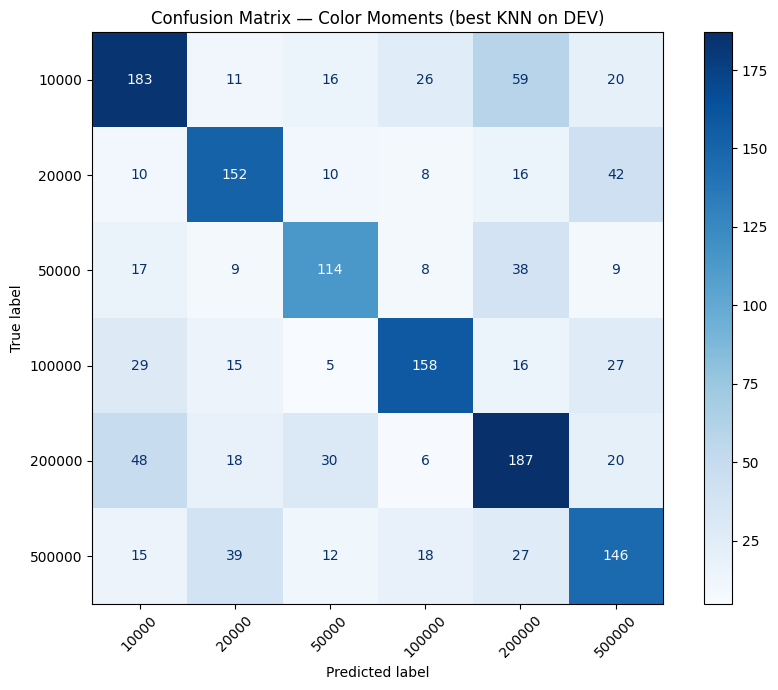

In [13]:
labels = np.sort(np.unique(y_train))
cm_moments = confusion_matrix(y_dev, y_dev_pred_moments, labels=labels)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_moments,
    display_labels=labels
)
fig, ax = plt.subplots(figsize=(9, 7))
disp.plot(ax=ax, cmap="Blues", values_format="d", xticks_rotation=45)
ax.set_title("Confusion Matrix — Color Moments (best KNN on DEV)")
plt.tight_layout()
plt.show()

In [14]:
report_moments = classification_report(
    y_dev, y_dev_pred_moments,
    labels=labels,
    output_dict=True,
    zero_division=0
)

per_class_moments = pd.DataFrame([
    {
        "denomination_vnd": int(label),
        "precision": report_moments[str(label)]["precision"],
        "recall": report_moments[str(label)]["recall"],
        "f1": report_moments[str(label)]["f1-score"],
        "support": int(report_moments[str(label)]["support"]),
    }
    for label in labels
])

display(per_class_moments)
print(f"Số ảnh đúng: {np.trace(cm_moments)}/{cm_moments.sum()}")

,denomination_vnd,precision,recall,f1,support
0,10000,0.605960,0.580952,0.593193,315
1,20000,0.622951,0.638655,0.630705,238
2,50000,0.609626,0.584615,0.596859,195
3,100000,0.705357,0.632000,0.666667,250
4,200000,0.545190,0.605178,0.573620,309
5,500000,0.553030,0.568093,0.560461,257


Số ảnh đúng: 940/1564


In [15]:
error_pairs_moments = []
for i in range(len(labels)):
    for j in range(i + 1, len(labels)):
        errors_ij = int(cm_moments[i, j])
        errors_ji = int(cm_moments[j, i])
        error_pairs_moments.append({
            "pair": f"{labels[i]} ↔ {labels[j]}",
            "true_i_pred_j": errors_ij,
            "true_j_pred_i": errors_ji,
            "total_errors": errors_ij + errors_ji,
        })

df_error_pairs_moments = (
    pd.DataFrame(error_pairs_moments)
    .sort_values("total_errors", ascending=False, kind="stable")
)
print("Top 5 cặp mệnh giá nhầm nhiều nhất:")
display(df_error_pairs_moments.head(5))

Top 5 cặp mệnh giá nhầm nhiều nhất:


,pair,true_i_pred_j,true_j_pred_i,total_errors
3,10000 ↔ 200000,59,48,107
8,20000 ↔ 500000,42,39,81
10,50000 ↔ 200000,38,30,68
2,10000 ↔ 100000,26,29,55
14,200000 ↔ 500000,20,27,47


## 8. Lưu kết quả để so sánh 4 feature

In [17]:
# Dùng đường dẫn tuyệt đối đến thư mục KNN để không phụ thuộc cwd của Jupyter.
output_dir = PROJECT_ROOT / "src" / "KNN" / "results"
output_dir.mkdir(parents=True, exist_ok=True)

summary_moments = pd.DataFrame([{
    "feature": "Color Moments RGB (mean + std + skewness)",
    "feature_dim": 9,
    "k": int(best_moments["k"]),
    "weights": str(best_moments["weights"]),
    "metric": str(best_moments["metric"]),
    "macro_f1": float(best_moments["macro_f1"]),
    "mae_vnd": float(best_moments["mae_vnd"]),
    "accuracy": float(best_moments["accuracy"]),
}])

df_results_moments.to_csv(output_dir / "moments_knn_grid_dev.csv", index=False)
summary_moments.to_csv(output_dir / "moments_best_dev.csv", index=False)
pd.DataFrame(cm_moments, index=labels, columns=labels).to_csv(
    output_dir / "moments_confusion_matrix_dev.csv"
)
per_class_moments.to_csv(output_dir / "moments_per_class_dev.csv", index=False)
df_error_pairs_moments.to_csv(output_dir / "moments_error_pairs_dev.csv", index=False)

print("Đã lưu kết quả vào:", output_dir)
display(summary_moments)

Đã lưu kết quả vào: C:\CS231\src\KNN\results


,feature,feature_dim,k,weights,metric,macro_f1,mae_vnd,accuracy
0,Color Moments RGB (mean + std + skewness),9,8,distance,cosine,0.603584,93331.202046,0.601023
